## Question 1 – Working with PDF

**1(a)** Install the required library and open the PDF. Print the total number of pages.

In [1]:
# Install the library needed to read PDF files
!pip install PyPDF2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 5.4 MB/s eta 0:00:00


In [2]:
# Create a PDF reader object and get the page count
from PyPDF2 import PdfReader
reader = PdfReader('Dancing_in_the_Rain.pdf')
print('Number of pages: ', len(reader.pages))

Number of pages:  3


**1(b)** Extract and print the text from the first page.

In [3]:
# Access the first page and extract its text
page = reader.pages[0]
text = page.extract_text()
print(text)

Dancing in the Rain for Life
Learning to live fully while the storm is still passing
Introduction
Every person meets rain sooner or later. Sometimes it arrives as a gentle drizzle: a
missed bus, a poor exam result, a quiet disappointment. Sometimes it comes as a
heavy storm that shakes the whole house of our life. Most of us spend years waiting
for the clouds to clear before we allow ourselves to feel happy. The idea of dancing
in the rain offers a braver and kinder choice. Instead of waiting for the storm to
pass, we learn to move, laugh and grow while the water is still falling.
Joy does not wait for perfect weather. It learns to walk, and
sometimes to dance, in the rain.
What Does It Mean?
Dancing in the rain is a metaphor, but it is also a practical way of living. It does not
mean that we ignore pain or pretend that every problem is small. It means that we
accept the weather we cannot control and decide, carefully and bravely, how we
will respond. A child understands this naturally

**1(c)** Extract and print text from every page of the PDF.

In [4]:
# Loop through all pages and extract text from each one
for page_number, page in enumerate(reader.pages, start=1):
    print(f'\n--- Page {page_number} ---')
    text = page.extract_text()
    print(text)


--- Page 1 ---
Dancing in the Rain for Life
Learning to live fully while the storm is still passing
Introduction
Every person meets rain sooner or later. Sometimes it arrives as a gentle drizzle: a
missed bus, a poor exam result, a quiet disappointment. Sometimes it comes as a
heavy storm that shakes the whole house of our life. Most of us spend years waiting
for the clouds to clear before we allow ourselves to feel happy. The idea of dancing
in the rain offers a braver and kinder choice. Instead of waiting for the storm to
pass, we learn to move, laugh and grow while the water is still falling.
Joy does not wait for perfect weather. It learns to walk, and
sometimes to dance, in the rain.
What Does It Mean?
Dancing in the rain is a metaphor, but it is also a practical way of living. It does not
mean that we ignore pain or pretend that every problem is small. It means that we
accept the weather we cannot control and decide, carefully and bravely, how we
will respond. A child understand

**1(d)** Search for the word "rain" and print the page numbers where it appears.

In [5]:
# Loop through pages and check if the word exists in the page text
search_word = 'rain'
for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text()
    if search_word.lower() in text.lower():
        print(f"'{search_word}' found on page {page_number}")

'rain' found on page 1
'rain' found on page 2
'rain' found on page 3


**1(e)** Count the total number of words in the whole PDF.

In [6]:
# Split text into words and keep adding the count for every page
word_count = 0
for page in reader.pages:
    text = page.extract_text()
    if text:
        word_count += len(text.split())
print('Total words:', word_count)

Total words: 1134


**1(f)** Extract and print the text of only the third page of the PDF.

In [7]:
# Page numbers start from 0, so the third page is reader.pages[2]
page = reader.pages[2]
print(page.extract_text())

Six Small Ways to Dance in the Rain
Dancing in the rain for life does not need a stage, a teacher or a special day. It
begins with small habits that anyone can practise. Here are six simple steps.
1. Breathe and pause. When the storm feels loud, breathe slowly for five minutes
and let your thoughts settle. Inner peace begins with a single quiet breath, and it
grows every time you return to it.
2. Practise self-care. Sleep well, eat simple food, drink water and walk in the
open air. Some people write self care on their calendar like an appointment, and
others say selfcare is only a trend. Yet the habit protects both the body and the
mind.
3. Choose positive thinking. Positive thinking does not deny the problem. It
simply asks a better question: what can I learn from this? A hopeful mind looks for
small lights instead of counting every shadow.
4. Count your blessings. Each evening, write down three things that went well.
Gratitude trains the eyes to notice the sunshine behind the clouds,

**1(g)** Copy the first page of the PDF into a new PDF file called `hello.pdf` and confirm it was created.

In [8]:
# PdfWriter creates a new PDF; add_page copies a page from the reader into it
from PyPDF2 import PdfWriter
writer = PdfWriter()
writer.add_page(reader.pages[0])
with open('hello.pdf', 'wb') as output:
    writer.write(output)
print('First page copied successfully!')

# Read the new file back to check it
check = PdfReader('hello.pdf')
print('Pages in hello.pdf:', len(check.pages))

First page copied successfully!
Pages in hello.pdf: 1


## Question 2 – Tokenization with spaCy

**2(a)** Load the spaCy model and tokenize a short sentence taken from the PDF.

In [9]:
# Load the English model, create a Doc object and print each token
import spacy
nlp = spacy.load('en_core_web_sm')
text = 'Joy does not wait for perfect weather.'
doc = nlp(text)
for token in doc:
    print(token.text)

Joy
does
not
wait
for
perfect
weather
.


**2(b)** Print the index of each token.

In [10]:
# token.i gives the position (index) of the token in the Doc
text = 'Joy does not wait for perfect weather.'
doc = nlp(text)
for token in doc:
    print(token.i, token.text)

0 Joy
1 does
2 not
3 wait
4 for
5 perfect
6 weather
7 .


**2(c)** Check whether each token is alphabetic, punctuation or space.

In [11]:
# is_alpha, is_punct and is_space are boolean attributes of each token
text = 'Joy does not wait for perfect weather.'
doc = nlp(text)
for token in doc:
    print(token.text, token.is_alpha, token.is_punct, token.is_space)

Joy True False False
does True False False
not True False False
wait True False False
for True False False
perfect True False False
weather True False False
. False True False


**2(d)** Tokenize a longer paragraph from the PDF and print only the alphabetic tokens.

In [12]:
# Keep only those tokens that contain alphabetic characters
text = 'Dancing in the rain is a metaphor, but it is also a practical way of living. It does not mean that we ignore pain or pretend that every problem is small.'
doc = nlp(text)
for token in doc:
    if token.is_alpha:
        print(token.text)

Dancing
in
the
rain
is
a
metaphor
but
it
is
also
a
practical
way
of
living
It
does
not
mean
that
we
ignore
pain
or
pretend
that
every
problem
is
small


**2(e)** Take a multi-sentence paragraph from the PDF. First split it into sentences, then print the tokens of each sentence.

In [13]:
# doc.sents splits the text into individual sentences
text = 'Life will always bring rain. Exams will be difficult, plans will change, and people will sometimes disappoint us. The goal is not to find a life without storms but to become a person who can laugh, learn and love in the middle of them.'
doc = nlp(text)
for sentence in doc.sents:
    print('\nSentence:', sentence.text)
    for token in sentence:
        print(token.text)


Sentence: Life will always bring rain.
Life
will
always
bring
rain
.

Sentence: Exams will be difficult, plans will change, and people will sometimes disappoint us.
Exams
will
be
difficult
,
plans
will
change
,
and
people
will
sometimes
disappoint
us
.

Sentence: The goal is not to find a life without storms but to become a person who can laugh, learn and love in the middle of them.
The
goal
is
not
to
find
a
life
without
storms
but
to
become
a
person
who
can
laugh
,
learn
and
love
in
the
middle
of
them
.


## Question 3 – Lemmatization with spaCy

**3(a)** Find the lemma of each word in a short sentence from the PDF.

In [14]:
# token.lemma_ returns the base form of the word
text = 'Children run outside when the first drops fall'
doc = nlp(text)
for token in doc:
    print(token.text, "->", token.lemma_)

Children -> child
run -> run
outside -> outside
when -> when
the -> the
first -> first
drops -> drop
fall -> fall


**3(b)** Lemmatize a longer sentence and join the lemmas into a single string.

In [15]:
# Join all lemmas with space to form a single lemmatized string
text = 'The best teachers of this lesson are often people who went through the hardest seasons'
doc = nlp(text)
lemmatized_text = " ".join(token.lemma_ for token in doc)
print(lemmatized_text)

the good teacher of this lesson be often people who go through the hard season


**3(c)** Show both the original word and its lemma together with the POS tag.

In [16]:
# Print original word, its POS tag and its lemma side by side
text = 'Resilient people still feel fear, sadness and stress'
doc = nlp(text)
for token in doc:
    print(token.text, "POS:", token.pos_, "Lemma:", token.lemma_)

Resilient POS: ADJ Lemma: resilient
people POS: NOUN Lemma: people
still POS: ADV Lemma: still
feel POS: VERB Lemma: feel
fear POS: NOUN Lemma: fear
, POS: PUNCT Lemma: ,
sadness POS: NOUN Lemma: sadness
and POS: CCONJ Lemma: and
stress POS: NOUN Lemma: stress


## Question 4 – Lemmatization with NLTK

**4(a)** Download the required NLTK resources and lemmatize a list of words.

In [17]:
# Download WordNet data and create a lemmatizer object
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [18]:
# Pass each word to the lemmatizer and print the result
words = ['children', 'playing', 'dancing', 'resilient', 'stronger']
for word in words:
    print(word, "->", lemmatizer.lemmatize(word))

children -> child
playing -> playing
dancing -> dancing
resilient -> resilient
stronger -> stronger


**4(b)** Lemmatize the same words by specifying the part-of-speech (verb).

In [19]:
# Tell the lemmatizer to treat the word as a verb
words = ['playing', 'dancing', 'learning']
for word in words:
    print(word, "->", lemmatizer.lemmatize(word, pos='v'))

playing -> play
dancing -> dance
learning -> learn


**4(c)** Lemmatize a short paragraph taken from the PDF using NLTK.

In [20]:
# Tokenize the text first, then lemmatize each alphabetic token
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download('punkt_tab')
text = 'Children run outside when the first drops fall, splash in puddles'
tokens = word_tokenize(text)
for word in tokens:
    if word.isalpha():
        print(word, "->", lemmatizer.lemmatize(word))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Children -> Children
run -> run
outside -> outside
when -> when
the -> the
first -> first
drops -> drop
fall -> fall
splash -> splash
in -> in
puddles -> puddle


## Question 5 – Stemming with NLTK and spaCy

**5(a)** Install NLTK, create a PorterStemmer and print the stem of each word in a list.

In [21]:
# Stemming removes prefixes/suffixes by fixed rules, e.g. connected -> connect, studies -> studi
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

words = ['dancing', 'danced', 'dances', 'dancer', 'laughed']
for word in words:
    print(word, '->', stemmer.stem(word))

dancing -> danc
danced -> danc
dances -> danc
dancer -> dancer
laughed -> laugh


**5(b)** Split a sentence from the PDF into words and print the stem of each word.

In [22]:
# split() breaks the sentence on spaces; each word is then stemmed
text = 'Children are playing outside and splashing in puddles'
words = text.split()
for word in words:
    print(word, '->', stemmer.stem(word))

Children -> children
are -> are
playing -> play
outside -> outsid
and -> and
splashing -> splash
in -> in
puddles -> puddl


**5(c)** Use a regular expression to extract the words from a sentence (in lower case) and print the stem of each word.

In [23]:
# re.findall with \b[a-zA-Z]+\b keeps only the words and drops punctuation
import re
text = 'Resilient people still feel fear, sadness and stress, but they keep dancing in the rain.'
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

for word in words:
    print(word, '->', stemmer.stem(word))

resilient -> resili
people -> peopl
still -> still
feel -> feel
fear -> fear
sadness -> sad
and -> and
stress -> stress
but -> but
they -> they
keep -> keep
dancing -> danc
in -> in
the -> the
rain -> rain


**5(d)** Stem every word of a sentence and join the stems into a single string. Print the original and the stemmed text.

In [24]:
# Collect the stems in a list and join them with spaces
text = 'The children are playing games and enjoying themselves in the rain.'
words = text.lower().split()

stemmed_words = []
for word in words:
    stemmed_words.append(stemmer.stem(word))

stemmed_text = ' '.join(stemmed_words)
print('Original:')
print(text)
print('\nStemmed:')
print(stemmed_text)

Original:
The children are playing games and enjoying themselves in the rain.

Stemmed:
the children are play game and enjoy themselv in the rain.


**5(e)** spaCy does not provide a built-in stemmer. Use spaCy to tokenize a sentence from the PDF and print the stem of each alphabetic token using NLTK's PorterStemmer.

In [25]:
# spaCy tokenizes the text; the PorterStemmer from NLTK does the stemming
text = 'Joy does not wait for perfect weather. Dancing in the rain is a practical way of living.'
doc = nlp(text)
for token in doc:
    if token.is_alpha:
        print(token.text, '->', stemmer.stem(token.text.lower()))

Joy -> joy
does -> doe
not -> not
wait -> wait
for -> for
perfect -> perfect
weather -> weather
Dancing -> danc
in -> in
the -> the
rain -> rain
is -> is
a -> a
practical -> practic
way -> way
of -> of
living -> live


## Question 6 – Stop Words Removal with spaCy

**6(a)** Check which words from a short list are stop words.

In [26]:
# token.is_stop returns True if the word is a stop word
words = ['the', 'is', 'rain', 'and', 'joy']
for word in words:
    doc = nlp(word)
    for token in doc:
        print(token.text, "->", token.is_stop)

the -> True
is -> True
rain -> False
and -> True
joy -> False


**6(b)** Remove stop words from a sentence taken from the PDF.

In [27]:
# Keep tokens that are neither stop words nor punctuation
text = 'Dancing in the rain is a metaphor but it is also a practical way of living'
doc = nlp(text)
words = []
for token in doc:
    if not token.is_stop and not token.is_punct:
        words.append(token.text)
print(words)

['Dancing', 'rain', 'metaphor', 'practical', 'way', 'living']


**6(c)** Create a simple function that removes stop words and punctuation, then test it on a sentence from the PDF.

In [28]:
# Function that filters out stop words and punctuation, then joins the rest
def remove_stopwords(text):
    doc = nlp(text)
    result = []
    for token in doc:
        if not token.is_stop and not token.is_punct:
            result.append(token.text)
    return " ".join(result)

text = 'The storm changes the traveller and the traveller can change the way the storm is remembered'
print(remove_stopwords(text))

storm changes traveller traveller change way storm remembered


## Question 7 – Stop Words Removal with NLTK

**7(a)** Load the English stop-word list and check a few words.

In [29]:
# Load the built-in English stop-word list into a set
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print(len(stop_words))

198


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [30]:
# Check membership of each word in the stop-word set
words = ['the', 'is', 'rain', 'and', 'joy']
for word in words:
    print(word, "->", word.lower() in stop_words)

the -> True
is -> True
rain -> False
and -> True
joy -> False


**7(b)** Remove stop words from a sentence taken from the PDF.

In [31]:
# Keep only those tokens that are not stop words and are alphabetic
from nltk.tokenize import word_tokenize
text = 'Most of us spend years waiting for the clouds to clear before we allow ourselves to feel happy'
tokens = word_tokenize(text)
result = []
for word in tokens:
    if word.lower() not in stop_words and word.isalpha():
        result.append(word)
print(result)

['us', 'spend', 'years', 'waiting', 'clouds', 'clear', 'allow', 'feel', 'happy']


## Question 8 – POS Tagging with spaCy

**8(a)** Assign POS tags to a simple sentence from the PDF.

In [32]:
# token.pos_ gives the coarse-grained part-of-speech tag
text = 'Joy does not wait for perfect weather.'
doc = nlp(text)
for token in doc:
    print(token.text, token.pos_)

Joy PROPN
does AUX
not PART
wait VERB
for ADP
perfect ADJ
weather NOUN
. PUNCT


**8(b)** Print the word, its POS tag and the explanation of the tag for a sentence from the PDF.

In [33]:
# spacy.explain() converts the POS tag into a readable description
text = 'Resilient people still feel fear, sadness and stress'
doc = nlp(text)
for token in doc:
    print(token.text, token.pos_, spacy.explain(token.pos_))

Resilient ADJ adjective
people NOUN noun
still ADV adverb
feel VERB verb
fear NOUN noun
, PUNCT punctuation
sadness NOUN noun
and CCONJ coordinating conjunction
stress NOUN noun


**8(c)** Extract only the nouns and verbs from a sentence taken from the PDF.

In [34]:
# Filter tokens whose POS tag is NOUN or VERB
text = 'Resilient people still feel fear, sadness and stress'
doc = nlp(text)
for token in doc:
    if token.pos_ in ['NOUN', 'VERB']:
        print(token.text, token.pos_)

people NOUN
feel VERB
fear NOUN
sadness NOUN
stress NOUN


**8(d)** Visualize the dependency parse of a sentence from the PDF using displacy.

In [35]:
# Render a dependency parse tree for the sentence
from spacy import displacy
text = 'Joy does not wait for perfect weather.'
doc = nlp(text)
options = {'compact': True, 'distance': 100}
displacy.render(doc, style='dep', options=options, jupyter=True)

## Question 9 – POS Tagging with NLTK

**9(a)** Download the required tagger and tag a simple sentence.

In [36]:
# Tokenize the sentence and assign POS tags using NLTK
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
sentence = 'Children run outside when the first drops fall.'
words = nltk.word_tokenize(sentence)
tags = nltk.pos_tag(words)
for word, tag in tags:
    print(word, '->', tag)

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


Children -> NNP
run -> VB
outside -> RB
when -> WRB
the -> DT
first -> JJ
drops -> VBZ
fall -> NN
. -> .


**9(b)** Identify only the nouns in the following sentence.

In [37]:
# Keep only tokens whose tag starts with NN (nouns)
sentence = 'Resilient people still feel fear, sadness and stress.'
words = nltk.word_tokenize(sentence)
tags = nltk.pos_tag(words)
for word, tag in tags:
    if tag.startswith('NN'):
        print(word)

people
sadness
stress


**9(c)** Identify the verbs in the following sentence.

In [38]:
# Keep only tokens whose tag starts with VB (verbs)
sentence = 'They talk to friends, rest when they are tired, and try again after they have failed.'
words = nltk.word_tokenize(sentence)
tags = nltk.pos_tag(words)
for word, tag in tags:
    if tag.startswith('VB'):
        print(word, '->', tag)

talk -> VBP
are -> VBP
tired -> VBN
try -> VB
have -> VBP
failed -> VBN


## Question 10– Named Entity Recognition with spaCy

**10(a)** Extract named entities from a short sentence that contains person and place names from the PDF.

In [39]:
# doc.ents contains the named entities found by spaCy
text = 'Viktor Frankl was a psychiatrist from Vienna'
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

Viktor Frankl PERSON
Vienna GPE


**10(b)** Extract entities from the sentence about Nelson Mandela.

In [40]:
# Loop through the entities and print text along with its label
text = 'Nelson Mandela spent twenty-seven years in prison in South Africa'
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

Nelson Mandela PERSON
twenty-seven years DATE
South Africa GPE


**10(c)** Extract entities from the Mumbai story paragraph.

In [41]:
# Extract all named entities from the longer paragraph
text = 'In March 2024, a schoolteacher named Meera Sharma lost her job when her school closed in Mumbai. A retired doctor from London, Arun Patel, donated $2,000 for new speakers.'
doc = nlp(text)
for ent in doc.ents:
    print(ent.text, ent.label_)

March 2024 DATE
Meera Sharma PERSON
Mumbai GPE
London GPE
Arun Patel PERSON
2,000 MONEY


**10(d)** Visualize the named entities in a sentence from the PDF using displacy.

In [42]:
# Highlight named entities in the text using displacy
from spacy import displacy
text = 'Viktor Frankl was a psychiatrist from Vienna. Nelson Mandela spent twenty-seven years in prison in South Africa.'
doc = nlp(text)
displacy.render(doc, style='ent', jupyter=True)

**10(e)** Count how many entities of each type (PERSON, GPE, DATE, MONEY, etc.) are found in the paragraphs from the PDF and show the result as a bar chart using matplotlib.

Counter({'PERSON': 4, 'GPE': 4, 'DATE': 2, 'MONEY': 1})


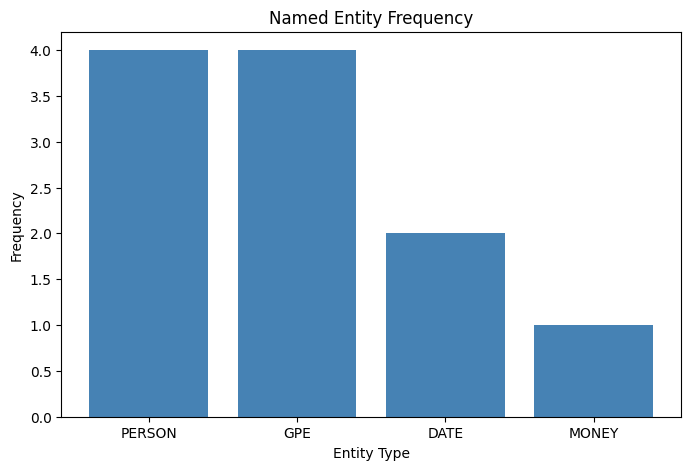

In [43]:
# Count the entity labels with Counter and plot them as a bar chart
import matplotlib.pyplot as plt
from collections import Counter

text = 'Viktor Frankl was a psychiatrist from Vienna. Nelson Mandela spent twenty-seven years in prison in South Africa. In March 2024, a schoolteacher named Meera Sharma lost her job when her school closed in Mumbai. A retired doctor from London, Arun Patel, donated $2,000 for new speakers.'
doc = nlp(text)

entity_counts = Counter(ent.label_ for ent in doc.ents)
print(entity_counts)

plt.figure(figsize=(8, 5))
plt.bar(entity_counts.keys(), entity_counts.values(), color='steelblue')
plt.xlabel('Entity Type')
plt.ylabel('Frequency')
plt.title('Named Entity Frequency')
plt.show()

## Question 11 – Named Entity Recognition with NLTK

**11(a)** Download the required resources and perform basic NER on a sentence.

In [44]:
# Perform NER by first POS-tagging and then chunking with NLTK
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')
sentence = 'Viktor Frankl was a psychiatrist from Vienna.'
words = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(words)
tree = nltk.ne_chunk(pos_tags)
print(tree)

[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker.zip.
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker_tab.zip.
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.


(S
  (PERSON Viktor/NNP)
  (PERSON Frankl/NNP)
  was/VBD
  a/DT
  psychiatrist/NN
  from/IN
  (GSP Vienna/NNP)
  ./.)


**11(b)** Extract person names from the following sentence.

In [45]:
# Check the chunk label and print only PERSON entities
sentence = 'Nelson Mandela spent twenty-seven years in prison in South Africa.'
words = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(words)
tree = nltk.ne_chunk(pos_tags)
for chunk in tree:
    if hasattr(chunk, 'label'):
        if chunk.label() == 'PERSON':
            print('Person:', ''.join(c[0] for c in chunk))

Person: Nelson
Person: Mandela


**11(c)** Create a small function that returns a list of entities and test it on a sentence.

In [46]:
# Function that returns a list of (entity, label) pairs
def extract_entities(sentence):
    words = nltk.word_tokenize(sentence)
    pos_tags = nltk.pos_tag(words)
    tree = nltk.ne_chunk(pos_tags)
    entities = []
    for chunk in tree:
        if hasattr(chunk, 'label'):
            entity = ''.join(word for word, tag in chunk)
            entities.append((entity, chunk.label()))
    return entities

sentence = 'She started free dance classes for children on the terrace of her building.'
print(extract_entities(sentence))

[]


## Question 12 – Vocabulary and Matching

**12(a)** Create a Matcher and add patterns for the phrase "dancing in the rain" (with and without hyphen / space variations).

In [47]:
# Define token patterns and add them to the Matcher
from spacy.matcher import Matcher
matcher = Matcher(nlp.vocab)
pattern1 = [{'LOWER': 'dancing'}, {'LOWER': 'in'}, {'LOWER': 'the'}, {'LOWER': 'rain'}]
pattern2 = [{'LOWER': 'dancing'}, {'IS_PUNCT': True}, {'LOWER': 'in'}, {'LOWER': 'the'}, {'LOWER': 'rain'}]
matcher.add('DancingInTheRain', [pattern1, pattern2])

**12(b)** Apply the matcher on a short text taken from the PDF and print the matches.

In [48]:
# Run the matcher on the Doc and print match id, start, end and text
doc = nlp('The idea of dancing in the rain offers a braver and kinder choice. Dancing in the rain for life is a practical way of living.')
found_matches = matcher(doc)
print(found_matches)
for match_id, start, end in found_matches:
    string_id = nlp.vocab.strings[match_id]
    span = doc[start:end]
    print(match_id, string_id, start, end, span.text)

[(12803273357881402929, 3, 7), (12803273357881402929, 14, 18)]
12803273357881402929 DancingInTheRain 3 7 dancing in the rain
12803273357881402929 DancingInTheRain 14 18 Dancing in the rain


**12(c)** Use PhraseMatcher to find the key phrases "resilience", "courage", "self-care" and "positive thinking".

In [49]:
# Create phrase patterns and add them to PhraseMatcher
from spacy.matcher import PhraseMatcher
phrase_matcher = PhraseMatcher(nlp.vocab)
phrase_list = ['resilience', 'courage', 'self-care', 'positive thinking']
phrase_patterns = [nlp(text) for text in phrase_list]
phrase_matcher.add('KeyThemes', None, *phrase_patterns)

In [50]:
# Run PhraseMatcher and print the matched spans
doc = nlp('Resilience is a skill that grows slowly. Courage over comfort is important. Practise self-care and positive thinking every day.')
matches = phrase_matcher(doc)
print(matches)
for match_id, start, end in matches:
    span = doc[start:end]
    print(span.text)

[(15291367390465926305, 15, 18), (15291367390465926305, 19, 21)]
self-care
positive thinking
